# Parte 3 · Flexibilidad y optimismo (3.1–3.3)

**Autor:** Jorge Ferguson · Grupo Taiwan

**Declaración de uso de IA:** se utilizó OpenAI Codex como herramienta de apoyo para comprender lo que pedía cada inciso del enunciado y como asistencia al escribir y depurar el código. El análisis, la verificación de resultados y su interpretación fueron revisados por el autor.

Ejecutar desde `notebooks/`, después de 04, en un kernel nuevo. Se leen la
partición y los hiperparámetros compartidos; no se ejecuta CV ni se cambia su
JSON. Todos son **regresores**, con predicciones sin recortar. 3.1 usa una
submuestra de 2.000 filas exclusivamente para verificar matrices completas;
3.2 vuelve a las 24.000 filas de entrenamiento y 6.000 de prueba.

In [1]:
import sys, json, gc, hashlib
from pathlib import Path
from time import perf_counter
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from datos import cargar_taiwan
from pesos import pesos_ols, pesos_ridge, pesos_knn, pesos_arbol
from bosque import pesos_bosque, verificar
from flexibilidad import (FAMILIAS, SEMILLA, crear_modelo, diagnostico_diseno,
    espectro_centrado, traza_ridge, diagonal_knn, diagonal_arbol, diagonal_bosque,
    registrar_procedencia)

inicio_notebook = perf_counter()
hp = json.loads(Path("../resultados/hiperparametros.json").read_text())
X_train, X_test, y_train, y_test, sd = cargar_taiwan("../data/taiwan_credit.csv")
assert X_train.shape == (24000, 23) and X_test.shape == (6000, 23)
original = pd.read_csv("../data/taiwan_credit.csv")
np.testing.assert_array_equal(y_train, original.loc[X_train.index, "default"].to_numpy(float))
np.testing.assert_array_equal(y_test, original.loc[X_test.index, "default"].to_numpy(float))
assert set(X_train.index).isdisjoint(X_test.index)
SEMILLA_SUBMUESTRA = 0
pos_sub = np.random.default_rng(SEMILLA_SUBMUESTRA).choice(len(X_train), size=2000, replace=False)
X_sub, y_sub = X_train.iloc[pos_sub].copy(), y_train[pos_sub].copy()
indices_sub = X_sub.index.to_numpy().copy()
assert len(np.unique(pos_sub)) == len(X_sub) == 2000
np.testing.assert_array_equal(indices_sub, X_train.index.to_numpy()[pos_sub])
np.testing.assert_array_equal(y_sub, original.loc[indices_sub, "default"].to_numpy(float))
TOL_PREDICCION = 1e-8  # estricta, usada por verificar
TOL_TRAZA = 1e-8       # absoluta para los escalares de 3.1
diagnostico_sub = diagnostico_diseno(X_sub)
d_sub = espectro_centrado(X_sub)
duplicados_sub = int(X_sub.duplicated(keep=False).sum())
display(pd.Series({**diagnostico_sub, "filas_en_grupos_duplicados": duplicados_sub}))
display(hp)

rango_aumentado               2.400000e+01
columnas_aumentadas           2.400000e+01
tolerancia_rango              4.716782e-11
condicion_diseno              1.713301e+01
condicion_gram                2.935399e+02
filas_en_grupos_duplicados    0.000000e+00
dtype: float64

{'lambda': 316.2278, 'k': 50, 'max_depth': 4, 'min_samples_leaf': 50}

## 3.1 · Cinco trazas y sus condiciones

El suavizador de **entrenamiento** es cuadrado: $\widehat y=Sy$ en las mismas
filas y orden usados para ajustar. Una matriz de consultas contra las 24.000
filas completas no sería el suavizador de esta submuestra. La selección es una
sola llamada a `default_rng(0).choice(24000, 2000, replace=False)`, sin ordenar
después: se registran las posiciones y los índices originales en procedencia.
No se buscan nuevas submuestras hasta obtener una respuesta deseada.

**OLS.** Con $A=[\mathbf1,X]$, $S=A(A^TA)^{-1}A^T$ es una proyección. Por
ciclicidad de la traza, $\mathrm{tr}(S)=\mathrm{tr}((A^TA)^{-1}A^TA)=p+1$ si
$A$ tiene rango completo. En general, usando la pseudoinversa, la proyección
tiene traza $\mathrm{rango}(A)$; el helper compartido usa una ecuación normal
que requiere invertibilidad. Se informa rango, tolerancia SVD y condiciones
de $A$ y $A^TA$. Si falla, se detiene con diagnóstico: no se cambia el helper
ni se elige otra muestra en silencio.

**Ridge.** Al dejar libre el intercepto y centrar **esta** muestra,
$S=\mathbf1\mathbf1^T/n+X_c(X_c^TX_c+\lambda I)^{-1}X_c^T$.
Con $X_c=UDV^T$, el primer término aporta 1 y los restantes aportan
$d_j^2/(d_j^2+\lambda)$; por tanto
$\mathrm{tr}(S)=1+\sum_j d_j^2/(d_j^2+\lambda)$.
La estandarización del entrenamiento completo no centra exactamente la
submuestra. Penalizar el intercepto cambiaría este resultado (véase 1.2).

**k-NN uniforme.** $S_{ii}=\mathbf1\{i\in N_k(x_i)\}/k$. Si todos incluyen
su propia fila, $\mathrm{tr}(S)=n/k$. Se consulta `kneighbors(X_sub)` de forma
explícita: `kneighbors()` sin X excluye el propio punto. Duplicados y empates
pueden alterar qué índices se eligen, especialmente con k pequeño. La traza
realizada se calcula con los índices devueltos y se contrasta con la diagonal
de la matriz completa. La consulta adicional k+1 solo diagnostica empates en
el límite; nunca se trunca para reemplazar la selección de k.

**Árbol.** Sin pesos de muestra, una hoja ocupada por $n_L$ filas tiene
$S_{ii}=1/n_L$ en esas filas: contribuye $n_L/n_L=1$. Así, la traza es el
número de hojas de entrenamiento, aunque la partición haya dependido de y.

**Bosque.** Con `bootstrap=False`, $S$ promedia las matrices de los árboles;
$S_{ii}=T^{-1}\sum_t1/n_{L_t(x_i)}$. Se calcula esta diagonal a partir de las
pertenencias reales, se suma y se contrasta con `np.trace(S)`. Como control
adicional, coincide con el promedio de los números de hojas. No se usan estas
ponderaciones en un bosque bootstrap, que necesita multiplicidades.

In [2]:
if diagnostico_sub["rango_aumentado"] != X_sub.shape[1] + 1:
    raise RuntimeError(f"Diseño deficiente de rango; diagnosticar antes de adaptar OLS: {diagnostico_sub}")
verificaciones = []
diagnostico_vecinos_sub = None
for nombre in FAMILIAS:
    t0 = perf_counter()
    modelo = crear_modelo(nombre, hp).fit(X_sub, y_sub)
    extras = {"auto_incluidos": None, "auto_excluidos": None,
              "traza_n_sobre_k": None, "empates_frontera_atol_1e_12": None,
              "hojas": None, "media_hojas_arboles": None, "error_diagonal_max": None}
    if nombre == "OLS":
        S = pesos_ols(X_sub, X_sub)
        traza_directa = float(diagnostico_sub["rango_aumentado"])
        formula = "rango([1,X]) = p+1 si rango completo"
    elif nombre == "Ridge":
        S = pesos_ridge(X_sub, X_sub, modelo.alpha)
        traza_directa = traza_ridge(d_sub, modelo.alpha)
        formula = "1 + suma d_j^2/(d_j^2+lambda), diseño centrado"
    elif nombre == "k-NN":
        S = pesos_knn(modelo, X_sub, len(X_sub))
        diag, diagnostico_vecinos_sub = diagonal_knn(modelo, X_sub, diagnosticar_empates=True)
        traza_directa = float(diag.sum())
        extras.update(diagnostico_vecinos_sub)
        extras["error_diagonal_max"] = float(np.max(np.abs(np.diag(S)-diag)))
        np.testing.assert_allclose(np.diag(S), diag, rtol=0, atol=1e-14)
        formula = "suma auto_inclusion_i/k; comparar n/k"
    elif nombre == "Árbol":
        S = pesos_arbol(modelo, X_sub, X_sub)
        diag = diagonal_arbol(modelo, X_sub)
        traza_directa = float(diag.sum())
        extras["hojas"] = int(modelo.get_n_leaves())
        extras["error_diagonal_max"] = float(np.max(np.abs(np.diag(S)-diag)))
        np.testing.assert_allclose(diag, np.diag(S), rtol=0, atol=1e-14)
        assert abs(traza_directa-modelo.get_n_leaves()) < TOL_TRAZA
        formula = "suma 1/n_hoja = numero de hojas"
    else:
        S = pesos_bosque(modelo, X_sub, X_sub)
        diag, media_hojas = diagonal_bosque(modelo, X_sub)
        traza_directa = float(diag.sum())
        extras["media_hojas_arboles"] = media_hojas
        extras["error_diagonal_max"] = float(np.max(np.abs(np.diag(S)-diag)))
        np.testing.assert_allclose(diag, np.diag(S), rtol=0, atol=1e-14)
        assert abs(traza_directa-media_hojas) < TOL_TRAZA
        formula = "suma_i promedio_t 1/n_hoja(t,i)"
    assert S.shape == (2000, 2000) and np.isfinite(S).all()
    extras["diagonal_min"] = float(np.diag(S).min())
    extras["diagonal_max"] = float(np.diag(S).max())
    np.testing.assert_array_equal(X_sub.index.to_numpy(), indices_sub)
    np.testing.assert_array_equal(y_sub, y_train[pos_sub])
    error_pred = float(verificar(S, y_sub, modelo.predict(X_sub), tol=TOL_PREDICCION))
    traza_matriz = float(np.trace(S))
    error_traza = abs(traza_directa-traza_matriz)
    assert error_traza < TOL_TRAZA
    if nombre == "k-NN" and extras["auto_incluidos"] == len(X_sub):
        assert abs(traza_matriz-len(X_sub)/modelo.n_neighbors) < TOL_TRAZA
    verificaciones.append({"familia": nombre, "n_train": len(X_sub), "p": X_sub.shape[1],
        **diagnostico_sub, "formula": formula, "traza_directa": traza_directa,
        "traza_matriz": traza_matriz, "discrepancia_traza": error_traza,
        "error_reconstruccion_max": error_pred, "tolerancia_traza": TOL_TRAZA,
        "tolerancia_prediccion_estricta": TOL_PREDICCION, **extras,
        "configuracion_json": json.dumps(modelo.get_params(), ensure_ascii=False, sort_keys=True),
        "segundos": perf_counter()-t0})
    print(f"{nombre}: traza={traza_matriz:.10f}; diferencia={error_traza:.2e}; "
          f"reconstrucción={error_pred:.2e}", flush=True)
    del S, modelo
    gc.collect()
verificacion = pd.DataFrame(verificaciones)
verificacion.to_csv("../resultados/parte3_verificacion_trazas.csv", index=False)
display(verificacion[["familia", "traza_directa", "traza_matriz", "discrepancia_traza",
                      "error_reconstruccion_max", "auto_incluidos", "hojas", "media_hojas_arboles"]])
display(diagnostico_vecinos_sub)
display(Markdown(f"La submuestra contiene {duplicados_sub} filas pertenecientes a grupos "
    f"de predictores duplicados. En k-NN se incluyen "
    f"{diagnostico_vecinos_sub['auto_incluidos']}/2000 observaciones propias; "
    f"se detectan {diagnostico_vecinos_sub['empates_frontera_atol_1e_12']} empates de distancia "
    "en la frontera k/k+1 (tolerancia absoluta 1e-12). La tabla registra el mínimo y máximo "
    "de cada diagonal. La igualdad n/k se ha contrastado, no impuesto."))

OLS: traza=24.0000000000; diferencia=0.00e+00; reconstrucción=6.79e-15


Ridge: traza=16.5395569866; diferencia=7.11e-15; reconstrucción=4.39e-15


k-NN: traza=40.0000000000; diferencia=0.00e+00; reconstrucción=1.11e-16


Árbol: traza=16.0000000000; diferencia=0.00e+00; reconstrucción=4.44e-16


Bosque: traza=29.7350000000; diferencia=0.00e+00; reconstrucción=7.77e-16


,familia,traza_directa,traza_matriz,discrepancia_traza,error_reconstruccion_max,auto_incluidos,hojas,media_hojas_arboles
0,OLS,24.000000,24.000000,0.000000e+00,6.786238e-15,NaN,NaN,NaN
1,Ridge,16.539557,16.539557,7.105427e-15,4.385381e-15,NaN,NaN,NaN
2,k-NN,40.000000,40.000000,0.000000e+00,1.110223e-16,2000.0,NaN,NaN
3,Árbol,16.000000,16.000000,0.000000e+00,4.440892e-16,NaN,16.0,NaN
4,Bosque,29.735000,29.735000,0.000000e+00,7.771561e-16,NaN,NaN,29.735


{'auto_incluidos': 2000,
 'auto_excluidos': 0,
 'traza_n_sobre_k': 40.0,
 'empates_frontera_atol_1e_12': 1}

La submuestra contiene 0 filas pertenecientes a grupos de predictores duplicados. En k-NN se incluyen 2000/2000 observaciones propias; se detectan 1 empates de distancia en la frontera k/k+1 (tolerancia absoluta 1e-12). La tabla registra el mínimo y máximo de cada diagonal. La igualdad n/k se ha contrastado, no impuesto.

## 3.2 · MSE de entrenamiento y prueba frente a tr(S)

Se usan **todas** las filas de la partición compartida (24.000/6.000).
El error es $\mathrm{MSE}=n^{-1}\sum_i(y_i-\widehat y_i)^2$ en cada conjunto.
Las rejillas son las de 03, pero aquí no se ejecuta CV ni se selecciona el JSON:
los mínimos de prueba son descriptivos y optimistas por inspeccionar muchas
alternativas. No sustituyen la selección mediante entrenamiento.

Cada punto usa el mismo ajuste para sus predicciones, errores y traza. OLS es
una referencia sin barrido. Se reutiliza una sola SVD para ridge; los otros
modelos se ajustan por configuración. Para k-NN cada k realiza su propia
consulta explícita: no se truncan vecinos de una búsqueda mayor, porque los
empates podrían cambiar la selección. La memoria se limita consultando por
lotes y liberando cada modelo; nunca se construye S de 24.000×24.000.

In [3]:
rejillas = {
    "Ridge": ("alpha", np.logspace(-2, 5, 15)),
    "k-NN": ("n_neighbors", [5,10,20,30,50,75,100,150,200,300,500]),
    "Árbol": ("max_depth", list(range(1,16))),
    "Bosque": ("min_samples_leaf", [1,2,5,10,20,50,100,200]),
}
diagnostico_completo = diagnostico_diseno(X_train)
d_completo = espectro_centrado(X_train)
assert diagnostico_completo["rango_aumentado"] == X_train.shape[1]+1
filas_curvas = []
inicio_barridos = perf_counter()
for nombre in FAMILIAS:
    parametro, valores = ("ninguno", [None]) if nombre == "OLS" else rejillas[nombre]
    for orden, valor in enumerate(valores):
        t0 = perf_counter()
        valor = valor.item() if isinstance(valor, np.generic) else valor
        modelo = crear_modelo(nombre, hp, None if nombre == "OLS" else parametro, valor)
        modelo.fit(X_train, y_train)
        pred_train = modelo.predict(X_train)
        pred_test_3 = modelo.predict(X_test)
        assert np.isfinite(pred_train).all() and np.isfinite(pred_test_3).all()
        auto_incluidos, media_hojas = None, None
        if nombre == "OLS":
            traza = float(diagnostico_completo["rango_aumentado"])
        elif nombre == "Ridge":
            traza = traza_ridge(d_completo, modelo.alpha)
        elif nombre == "k-NN":
            diag, auto = diagonal_knn(modelo, X_train)
            traza = float(diag.sum())
            auto_incluidos = auto["auto_incluidos"]
        elif nombre == "Árbol":
            traza = float(modelo.get_n_leaves())
        else:
            diag, media_hojas = diagonal_bosque(modelo, X_train)
            traza = float(diag.sum())
            assert abs(traza-media_hojas) < 1e-8
        mse_train = float(np.mean((y_train-pred_train)**2))
        mse_test = float(np.mean((y_test-pred_test_3)**2))
        filas_curvas.append({"familia": nombre, "parametro": parametro, "valor_parametro": valor,
            "orden_rejilla": orden, "n_train": len(X_train), "n_test": len(X_test),
            "traza": traza, "mse_train": mse_train, "mse_test": mse_test,
            "metrica": "MSE", "auto_incluidos_knn": auto_incluidos,
            "media_hojas_bosque": media_hojas,
            "configuracion_json": json.dumps(modelo.get_params(), ensure_ascii=False, sort_keys=True),
            "segundos": perf_counter()-t0})
        print(f"{nombre} {parametro}={valor}: traza={traza:.5f}; "
              f"MSE train={mse_train:.6f}, test={mse_test:.6f}; "
              f"{perf_counter()-t0:.1f}s", flush=True)
        del modelo, pred_train, pred_test_3
        gc.collect()
curvas = pd.DataFrame(filas_curvas)
assert len(curvas) == 1 + sum(len(v) for _,v in rejillas.values()) == 50
assert curvas[["traza", "mse_train", "mse_test"]].notna().all().all()
for familia, (parametro, valores) in rejillas.items():
    seleccion = curvas[curvas.familia == familia]
    np.testing.assert_array_equal(seleccion.valor_parametro.to_numpy(), np.asarray(valores))
    assert (seleccion.parametro == parametro).all()
    for fila in seleccion.itertuples():
        assert json.loads(fila.configuracion_json)[parametro] == fila.valor_parametro
assert (curvas.n_train == 24000).all() and (curvas.n_test == 6000).all()
# Empate exacto de MSE: gana el primer valor en el orden declarado de la rejilla.
minimos = curvas.loc[[curvas.index[curvas.familia == f][
    np.argmin(curvas.loc[curvas.familia == f, "mse_test"].to_numpy())] for f in FAMILIAS]].copy()
curvas["minimo_prueba_familia"] = curvas.index.isin(minimos.index)
assert curvas.groupby("familia").minimo_prueba_familia.sum().eq(1).all()
for f in FAMILIAS:
    assert curvas.loc[(curvas.familia == f) & curvas.minimo_prueba_familia, "mse_test"].iloc[0] == curvas.loc[curvas.familia == f, "mse_test"].min()
curvas.to_csv("../resultados/parte3_error_flexibilidad.csv", index=False)
segundos_barridos = perf_counter()-inicio_barridos
display(minimos[["familia", "parametro", "valor_parametro", "traza", "mse_train", "mse_test"]])
print(f"Barridos completos: {len(curvas)} configuraciones en {segundos_barridos:.1f}s")

OLS ninguno=None: traza=24.00000; MSE train=0.151712, test=0.147914; 0.1s


Ridge alpha=0.01: traza=23.99993; MSE train=0.151712, test=0.147914; 0.0s


Ridge alpha=0.03162277660168379: traza=23.99979; MSE train=0.151712, test=0.147914; 0.0s


Ridge alpha=0.1: traza=23.99934; MSE train=0.151712, test=0.147914; 0.0s


Ridge alpha=0.31622776601683794: traza=23.99790; MSE train=0.151712, test=0.147914; 0.0s


Ridge alpha=1.0: traza=23.99337; MSE train=0.151712, test=0.147914; 0.0s


... (42 outputs left out)

Bosque min_samples_leaf=100: traza=180.64000; MSE train=0.126999, test=0.129932; 4.0s


Bosque min_samples_leaf=200: traza=90.80000; MSE train=0.131518, test=0.130701; 3.7s


,familia,parametro,valor_parametro,traza,mse_train,mse_test
0,OLS,ninguno,NaN,24.000000,0.151712,0.147914
10,Ridge,alpha,316.227766,22.417062,0.151721,0.147906
22,k-NN,n_neighbors,100.000000,240.000000,0.138597,0.139091
31,Árbol,max_depth,5.000000,32.000000,0.135119,0.133837
47,Bosque,min_samples_leaf,50.000000,355.235000,0.119105,0.129757


Barridos completos: 50 configuraciones en 156.2s


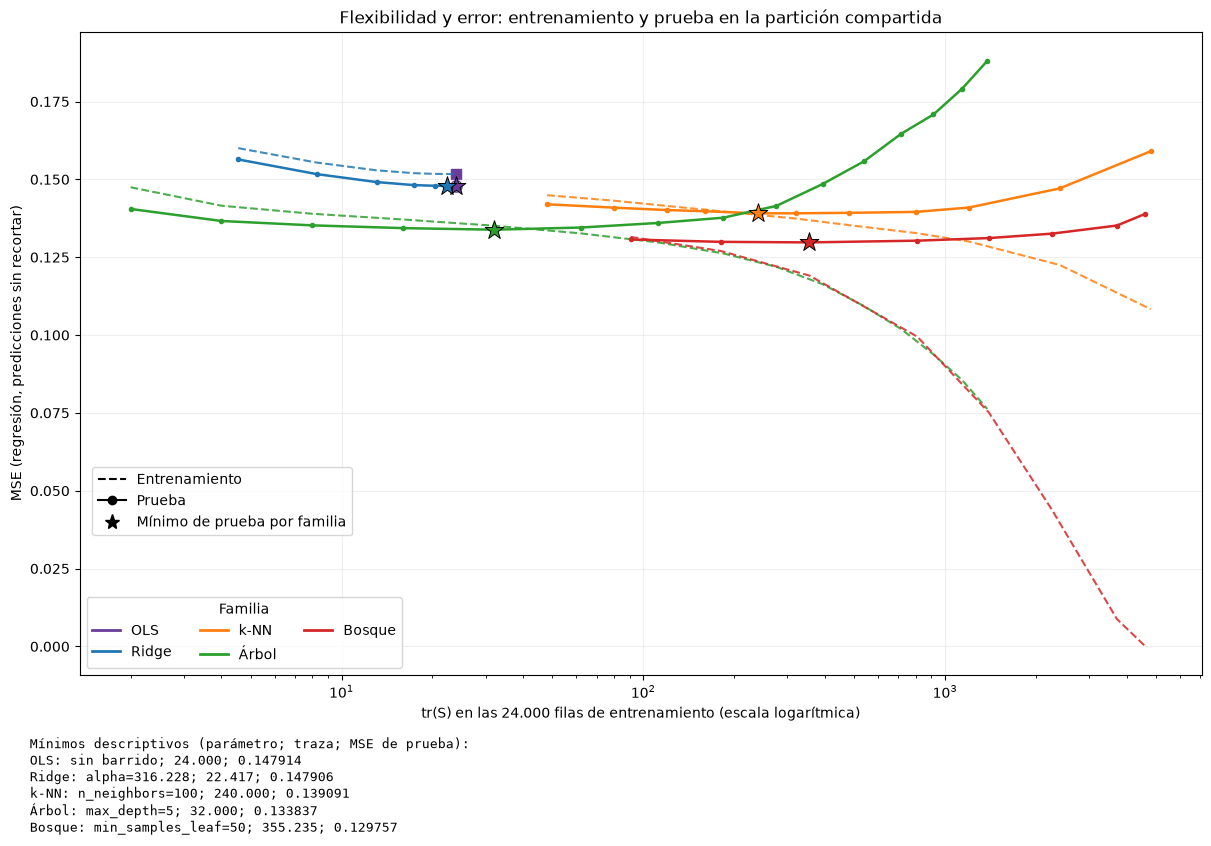

In [4]:
from matplotlib.lines import Line2D
colores = dict(zip(FAMILIAS, ["#6a3d9a", "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]))
fig, ax = plt.subplots(figsize=(12, 7.2), layout="constrained")
for nombre in FAMILIAS:
    datos_f = curvas[curvas.familia == nombre].sort_values("traza")
    color = colores[nombre]
    if nombre == "OLS":
        ax.scatter(datos_f.traza, datos_f.mse_train, marker="s", s=50, color=color)
        ax.scatter(datos_f.traza, datos_f.mse_test, marker="o", s=65, facecolors="white", edgecolors=color)
    else:
        ax.plot(datos_f.traza, datos_f.mse_train, "--", color=color, lw=1.5, alpha=.85)
        ax.plot(datos_f.traza, datos_f.mse_test, "o-", color=color, ms=3, lw=1.8)
    minimo = minimos[minimos.familia == nombre].iloc[0]
    ax.scatter([minimo.traza], [minimo.mse_test], marker="*", s=200,
               color=color, edgecolor="black", linewidth=.7, zorder=8)
ax.set_xscale("log")
ax.set(xlabel="tr(S) en las 24.000 filas de entrenamiento (escala logarítmica)",
       ylabel="MSE (regresión, predicciones sin recortar)",
       title="Flexibilidad y error: entrenamiento y prueba en la partición compartida")
ax.grid(alpha=.2)
familias_leyenda = [Line2D([0],[0],color=colores[f],lw=2,label=f) for f in FAMILIAS]
leyenda_1 = ax.legend(handles=familias_leyenda, loc="lower left", title="Familia", ncol=3)
ax.add_artist(leyenda_1)
ax.legend(handles=[Line2D([0],[0],color="black",ls="--",label="Entrenamiento"),
                   Line2D([0],[0],color="black",marker="o",label="Prueba"),
                   Line2D([0],[0],color="black",marker="*",ls="",markersize=11,label="Mínimo de prueba por familia")],
          loc="center left", bbox_to_anchor=(0.005, .27))
texto_minimos = "Mínimos descriptivos (parámetro; traza; MSE de prueba):\n" + "\n".join(
    f"{r.familia}: {'sin barrido' if r.familia == 'OLS' else r.parametro+'='+format(r.valor_parametro, '.6g')}; "
    f"{r.traza:.3f}; {r.mse_test:.6f}" for r in minimos.itertuples())
fig.text(.02, -.015, texto_minimos, fontsize=9, va="top", family="monospace")
fig.savefig("../figs/parte3_error_flexibilidad.png", dpi=170, bbox_inches="tight")
plt.show()

### Lectura y límites

Más traza significa menos suavizado en estas familias, pero las curvas deben
leerse dentro de la familia y con su configuración. La traza de una partición
realizada es una descripción algebraica; no equivale automáticamente a los
grados de libertad definidos por covarianza en un árbol adaptativo. Una
trayectoria no monótona no debe esconderse: profundidad es un límite, hojas y
particiones se ajustan de nuevo, y un mismo número de hojas puede representar
reglas distintas. En k-NN el conjunto de vecinos puede cambiar con k y con
empates, por lo que el MSE de entrenamiento no tiene una ley de monotonía
universal. El bosque promedia particiones adaptativas.

In [5]:
lecturas = []
for nombre in FAMILIAS:
    datos_f = curvas[curvas.familia == nombre].sort_values(["traza", "orden_rejilla"])
    m = minimos[minimos.familia == nombre].iloc[0]
    subidas_train = int((np.diff(datos_f.mse_train) > 1e-12).sum())
    lecturas.append(f"- **{nombre}:** mínimo de prueba {m.mse_test:.6f}, traza {m.traza:.3f}, "
        + ("referencia OLS" if nombre == "OLS" else f"{m.parametro}={m.valor_parametro:g}")
        + f". MSE de entrenamiento en ese ajuste: {m.mse_train:.6f}. "
        + (f"Al ordenar por traza, hay {subidas_train} aumentos de MSE de entrenamiento; "
           "la tabla conserva también el orden original de la rejilla." if len(datos_f)>1 else
           "Es un único ajuste, no una curva regularizada."))
display(Markdown("\n".join(lecturas)))
comparacion_extremos = []
for nombre in FAMILIAS[1:]:
    datos_f = curvas[curvas.familia == nombre]
    suave = datos_f.loc[datos_f.traza.idxmin()]
    flexible = datos_f.loc[datos_f.traza.idxmax()]
    mejor = minimos[minimos.familia == nombre].iloc[0]
    comparacion_extremos.append(
        f"- **{nombre}:** del extremo menos flexible al mínimo de prueba y al extremo "
        f"más flexible, el MSE de prueba es {suave.mse_test:.6f} → {mejor.mse_test:.6f} "
        f"→ {flexible.mse_test:.6f}; el de entrenamiento es {suave.mse_train:.6f} "
        f"→ {mejor.mse_train:.6f} → {flexible.mse_train:.6f}.")
display(Markdown("\n".join(comparacion_extremos)))
ols_fila = curvas[curvas.familia == "OLS"].iloc[0]
ridge_minimo = minimos[minimos.familia == "Ridge"].iloc[0]
display(Markdown(
    f"La ganancia mínima de ridge frente a OLS en este test es "
    f"{ols_fila.mse_test-ridge_minimo.mse_test:.8f}, pequeña frente a las diferencias "
    "entre familias. Árbol, k-NN y bosque muestran el compromiso: la flexibilidad extrema "
    "reduce el error de entrenamiento y empeora el de prueba respecto a sus mínimos interiores. "
    f"En OLS el MSE test ({ols_fila.mse_test:.6f}) es menor que el train "
    f"({ols_fila.mse_train:.6f}); una realización con covariables distintas no tiene "
    "por qué presentar un gap positivo ni contradice una identidad de optimismo esperado "
    "con respuestas independientes en las mismas X."))
display(Markdown(
    "Las estrellas identifican mínimos observados en este test, no estimaciones independientes "
    "del desempeño tras selección. La comparación con Gregorio es conceptual: sus 3.000 "
    "covariables fijas, señal de referencia y ruido simulado cambian la población, la escala de "
    "la traza y el mecanismo de respuesta. Ni la traza cruda ni el gap de estas curvas deben "
    "copiarse como predicción numérica de su experimento."))

- **OLS:** mínimo de prueba 0.147914, traza 24.000, referencia OLS. MSE de entrenamiento en ese ajuste: 0.151712. Es un único ajuste, no una curva regularizada.
- **Ridge:** mínimo de prueba 0.147906, traza 22.417, alpha=316.228. MSE de entrenamiento en ese ajuste: 0.151721. Al ordenar por traza, hay 0 aumentos de MSE de entrenamiento; la tabla conserva también el orden original de la rejilla.
- **k-NN:** mínimo de prueba 0.139091, traza 240.000, n_neighbors=100. MSE de entrenamiento en ese ajuste: 0.138597. Al ordenar por traza, hay 0 aumentos de MSE de entrenamiento; la tabla conserva también el orden original de la rejilla.
- **Árbol:** mínimo de prueba 0.133837, traza 32.000, max_depth=5. MSE de entrenamiento en ese ajuste: 0.135119. Al ordenar por traza, hay 0 aumentos de MSE de entrenamiento; la tabla conserva también el orden original de la rejilla.
- **Bosque:** mínimo de prueba 0.129757, traza 355.235, min_samples_leaf=50. MSE de entrenamiento en ese ajuste: 0.119105. Al ordenar por traza, hay 0 aumentos de MSE de entrenamiento; la tabla conserva también el orden original de la rejilla.

- **Ridge:** del extremo menos flexible al mínimo de prueba y al extremo más flexible, el MSE de prueba es 0.156397 → 0.147906 → 0.147914; el de entrenamiento es 0.160028 → 0.151721 → 0.151712.
- **k-NN:** del extremo menos flexible al mínimo de prueba y al extremo más flexible, el MSE de prueba es 0.141997 → 0.139091 → 0.159033; el de entrenamiento es 0.144918 → 0.138597 → 0.108317.
- **Árbol:** del extremo menos flexible al mínimo de prueba y al extremo más flexible, el MSE de prueba es 0.140495 → 0.133837 → 0.188043; el de entrenamiento es 0.147466 → 0.135119 → 0.076278.
- **Bosque:** del extremo menos flexible al mínimo de prueba y al extremo más flexible, el MSE de prueba es 0.130701 → 0.129757 → 0.138854; el de entrenamiento es 0.131518 → 0.119105 → 0.000201.

La ganancia mínima de ridge frente a OLS en este test es 0.00000824, pequeña frente a las diferencias entre familias. Árbol, k-NN y bosque muestran el compromiso: la flexibilidad extrema reduce el error de entrenamiento y empeora el de prueba respecto a sus mínimos interiores. En OLS el MSE test (0.147914) es menor que el train (0.151712); una realización con covariables distintas no tiene por qué presentar un gap positivo ni contradice una identidad de optimismo esperado con respuestas independientes en las mismas X.

Las estrellas identifican mínimos observados en este test, no estimaciones independientes del desempeño tras selección. La comparación con Gregorio es conceptual: sus 3.000 covariables fijas, señal de referencia y ruido simulado cambian la población, la escala de la traza y el mecanismo de respuesta. Ni la traza cruda ni el gap de estas curvas deben copiarse como predicción numérica de su experimento.

## 3.3 · Optimismo bajo pérdida cuadrática: derivación

Fijemos las covariables $X=(x_1,\ldots,x_n)$ y, cuando corresponda, una
aleatoriedad algorítmica $R$ independiente del ruido. Supongamos
$y=f+\varepsilon$, con $f_i=E[y_i\mid X]$,
$E[\varepsilon\mid X,R]=0$ y
$\operatorname{Cov}(\varepsilon\mid X,R)=\sigma^2I$.
Sea $\widehat y=Sy$, con $S=S(X,R)$ **independiente de las respuestas y del
ruido observado**. Las expectativas siguientes condicionan en $X,R$.

Como $f$ y $S$ son fijos en esta comparación,
$$\operatorname{Cov}(\widehat y_i,y_i\mid X,R)
=\operatorname{Cov}\left(\sum_j S_{ij}\varepsilon_j,\varepsilon_i\mid X,R\right)
=\sum_j S_{ij}\operatorname{Cov}(\varepsilon_j,\varepsilon_i\mid X,R)
=S_{ii}\sigma^2.$$

Ahora generemos **nuevas respuestas independientes en las mismas covariables**:
$y^*=f+\varepsilon^*$, con el mismo primer y segundo momento e independencia
respecto al entrenamiento y su ajuste. Definimos
$$\mathrm{err}_{\rm train}=\frac1n\sum_i(y_i-\widehat y_i)^2,\qquad
\mathrm{err}_{\rm nuevo}=\frac1n\sum_i(y_i^*-\widehat y_i)^2.$$
El optimismo esperado es $E[\mathrm{err}_{\rm nuevo}-\mathrm{err}_{\rm train}\mid X,R]$.
Al expandir un sumando se cancelan los términos $\widehat y_i^2$ y, en
esperanza, $y_i^{*2}$ con $y_i^2$, porque las dos respuestas tienen iguales
segundos momentos. Queda
$$E[(y_i^*-\widehat y_i)^2-(y_i-\widehat y_i)^2\mid X,R]
=2\{E[y_i\widehat y_i\mid X,R]-E[y_i^*\widehat y_i\mid X,R]\}.$$
Por independencia, $E[y_i^*\widehat y_i\mid X,R]=f_iE[\widehat y_i\mid X,R]$,
y $E[y_i\mid X,R]=f_i$. Por tanto el término entre llaves es la covarianza:
$$E[\mathrm{err}_{\rm nuevo}-\mathrm{err}_{\rm train}\mid X,R]
=\frac2n\sum_i\operatorname{Cov}(\widehat y_i,y_i\mid X,R)
=\boxed{\frac{2\sigma^2}{n}\operatorname{tr}(S)}.$$
Si $R$ es aleatorio e independiente, se puede promediar también sobre R.
**No se necesita normalidad**, sino los momentos e independencias indicados;
el sesgo respecto a f se cancela en esta diferencia.

### Dónde deja de aplicar el argumento fijo

- **Árboles y bosques adaptativos:** después del ajuste existe una matriz que
  reproduce la predicción, pero las particiones se eligieron usando y.
  $S(y)y$ no permite sacar S de la covarianza como si fuera constante.
  Condicionar después en la partición elegida no recupera automáticamente la
  distribución de ruido original. La traza realizada no captura todo el coste
  de buscar particiones. No se afirma aquí un exceso numérico sin simularlo.
- **Selección de hiperparámetros:** incluso ridge o k-NN, con geometría fija
  para parámetros prefijados, adquieren dependencia de y si se escogen sus
  parámetros con las mismas respuestas. La identidad de configuración fija
  omite ese coste de selección; el JSON de CV no lo elimina por sí solo.
- **Etiquetas binarias:** $\operatorname{Var}(y_i\mid X)=p_i(1-p_i)$ puede
  variar entre clientes. Ser 0/1 no implica homocedasticidad. Con covarianza
  general $\Sigma$ y S independiente, la expresión es
  $2\operatorname{tr}(S\Sigma)/n$, no necesariamente $2\sigma^2\operatorname{tr}(S)/n$.
- **Gap test/train ordinario:** en 3.2 cambian las covariables, el tamaño y
  la composición de los conjuntos. Ese gap no es la comparación pareada de
  respuestas independientes en las mismas X y no debe igualarse sin más a la
  fórmula anterior.

### Resumen

El ajuste ve el ruido de entrenamiento y se beneficia
de él al evaluarse sobre esas mismas respuestas. La nueva respuesta en la
misma X no comparte ese ruido. Al restar los errores cuadrados queda dos
veces la covarianza entre respuesta y ajuste; para un suavizador independiente
de y, la diagonal mide cuánto ruido propio regresa a cada predicción.

In [6]:
artefactos_3 = ["resultados/parte3_verificacion_trazas.csv",
    "resultados/parte3_error_flexibilidad.csv", "figs/parte3_error_flexibilidad.png"]
registro_3 = registrar_procedencia("3.1–3.3", {
    "n_train": len(X_train), "n_test": len(X_test), "n_submuestra": len(X_sub),
    "semilla_submuestra": SEMILLA_SUBMUESTRA,
    "seleccion": "numpy.random.default_rng(0).choice(n_train, size=2000, replace=False), orden sin ordenar",
    "posiciones_entrenamiento_submuestra": pos_sub.tolist(), "indices_csv_submuestra": indices_sub.tolist(),
    "indices_train_sha256": hashlib.sha256(X_train.index.to_numpy().tobytes()).hexdigest(),
    "indices_test_sha256": hashlib.sha256(X_test.index.to_numpy().tobytes()).hexdigest(),
    "metrica": "MSE = media((y-prediccion)^2), predicciones sin recortar",
    "diagnostico_diseno_completo": diagnostico_completo,
    "duplicados_submuestra": duplicados_sub, "diagnostico_vecinos_submuestra": diagnostico_vecinos_sub,
    "rejillas": {f: {"parametro": p, "valores": list(map(float,v))} for f,(p,v) in rejillas.items()},
    "n_configuraciones": len(curvas), "desempate_minimos": "primer valor de rejilla en igualdad exacta de MSE",
    "tolerancia_traza": TOL_TRAZA, "tolerancia_prediccion_estricta": TOL_PREDICCION,
    "segundos_barridos": segundos_barridos, "segundos_notebook": perf_counter()-inicio_notebook,
}, artefactos_3)
print(f"Verificación completa; RSS máximo del kernel: {registro_3['rss_maximo_proceso_MiB']:.1f} MiB")

Verificación completa; RSS máximo del kernel: 491.9 MiB
